# Series de tiempo 4 — Modelos autorregresivos, de media móvil, ARIMA y SARIMAX

**Continuación de los libros 0–3:** preparación y calendario → descomposición → suavización exponencial → **modelado de la dependencia temporal**.

En el libro 3 proyectamos nivel, tendencia y estacionalidad mediante SES, Holt y Holt-Winters. Ahora modelaremos la dependencia entre observaciones y entre las **innovaciones** (errores de predicción de un paso). Comenzaremos con procesos sintéticos cuyos parámetros conocemos; después incorporaremos diferenciación, estacionalidad y variables exógenas.

**Objetivos:**
1. Simular ruido blanco, AR(p), MA(q) y ARMA(p,q) y explicar sus mecanismos.
2. Interpretar ACF y PACF poblacionales y muestrales, incluidos sus límites.
3. Entender ARIMA(p,d,q), SARIMA(p,d,q)(P,D,Q,s) y SARIMAX.
4. Buscar órdenes con BIC y comprobar residuos y pronósticos fuera de muestra.
5. Elegir entre tiempo calendario y tiempo de negociación, sin inventar datos.

**Requisitos:** `numpy`, `pandas`, `matplotlib`, `statsmodels` (sin descargas externas para los ejercicios principales).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima_process import ArmaProcess, arma_acf, arma_pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})
SEMILLA = 2026

## 1. ¿Qué es estacionariedad y por qué importa?

En un proceso **débilmente estacionario**, la media y la varianza no cambian con el tiempo y la covarianza entre $X_t$ y $X_{t-k}$ depende únicamente del rezago $k$. Eso permite interpretar la ACF como una función del rezago y no de la fecha.

La **innovación** $\varepsilon_t$ es el componente nuevo e impredecible al observar el pasado del modelo. En nuestras simulaciones será ruido blanco gaussiano con media cero y varianza constante. Un proceso puede ser estacionario y tener autocorrelación; **estacionariedad no significa ruido blanco**.

La diferencia entre *dependencia de valores anteriores* (AR) y *dependencia de innovaciones anteriores* (MA) se entenderá mejor con procesos controlados.

## 2. Ruido blanco: referencia sin estructura temporal

$$X_t=\varepsilon_t,\qquad \varepsilon_t\sim \mathrm{WN}(0,\sigma^2).$$

Teóricamente $\rho(k)=0$ para todo $k>0$. En una muestra finita, las correlaciones estimadas **no serán exactamente cero**. Las bandas aproximadas $\pm 1.96/\sqrt{n}$ son una referencia puntual bajo ruido blanco; si examinamos muchos rezagos, algunos pueden salir de las bandas por azar.

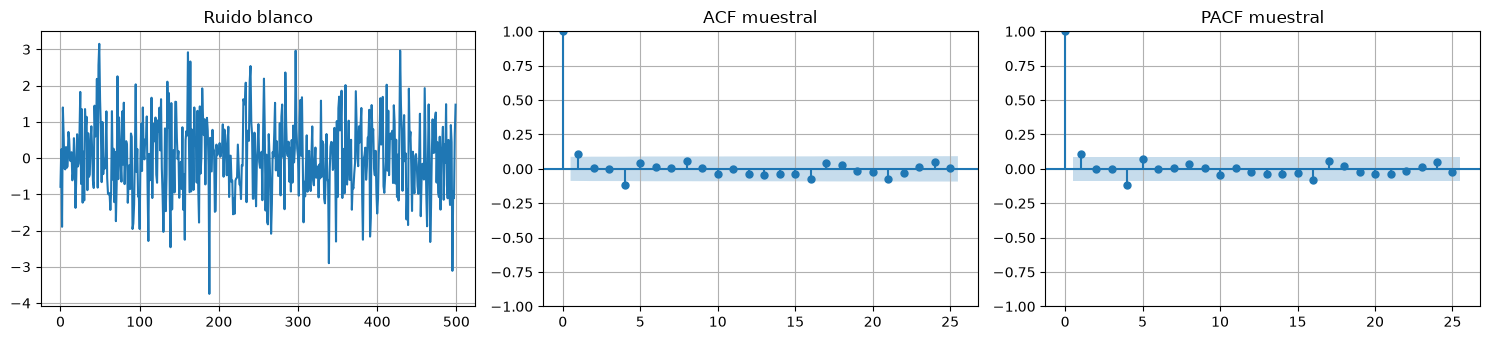

In [2]:
rng = np.random.default_rng(SEMILLA)
n = 500
ruido = pd.Series(rng.normal(size=n), name="Ruido blanco")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ruido.plot(ax=ax[0], title="Ruido blanco")
plot_acf(ruido, lags=25, ax=ax[1]); ax[1].set_title("ACF muestral")
plot_pacf(ruido, lags=25, ax=ax[2], method="ywm"); ax[2].set_title("PACF muestral")
plt.tight_layout(); plt.show()

## 3. La ACF y la PACF: qué miden

La **autocorrelación** en rezago $k$ mide la correlación lineal entre $X_t$ y $X_{t-k}$:

$$\rho(k)=\frac{\operatorname{Cov}(X_t,X_{t-k})}{\operatorname{Var}(X_t)}.$$

La **autocorrelación parcial** en rezago $k$ mide la asociación lineal entre $X_t$ y $X_{t-k}$ **después de controlar linealmente** por los rezagos intermedios $X_{t-1},\ldots,X_{t-k+1}$. Se puede interpretar como el coeficiente del rezago $k$ en una regresión lineal de $X_t$ sobre sus $k$ rezagos (con las condiciones habituales).

**No son reglas infalibles de identificación:** los patrones ideales corresponden a procesos puros y muestras grandes. En muestras reales, los órdenes pueden ser ambiguos.

## 4. Modelo autorregresivo AR(p)

$$X_t=c+\phi_1X_{t-1}+\cdots+\phi_pX_{t-p}+\varepsilon_t.$$

- AR(1): $X_t=\phi X_{t-1}+\varepsilon_t$ (media cero); para estacionariedad se requiere $|\phi|<1$.
- Si $\phi>0$, las correlaciones suelen decaer gradualmente y conservar signo; si $\phi<0$, suelen alternar signo.
- En un **AR(p) puro**, la **PACF poblacional se corta después del rezago $p$** y la ACF decae, a veces con oscilaciones.

**Precisión:** el corte es una propiedad poblacional; la PACF muestral fluctúa alrededor de cero incluso después de $p$.

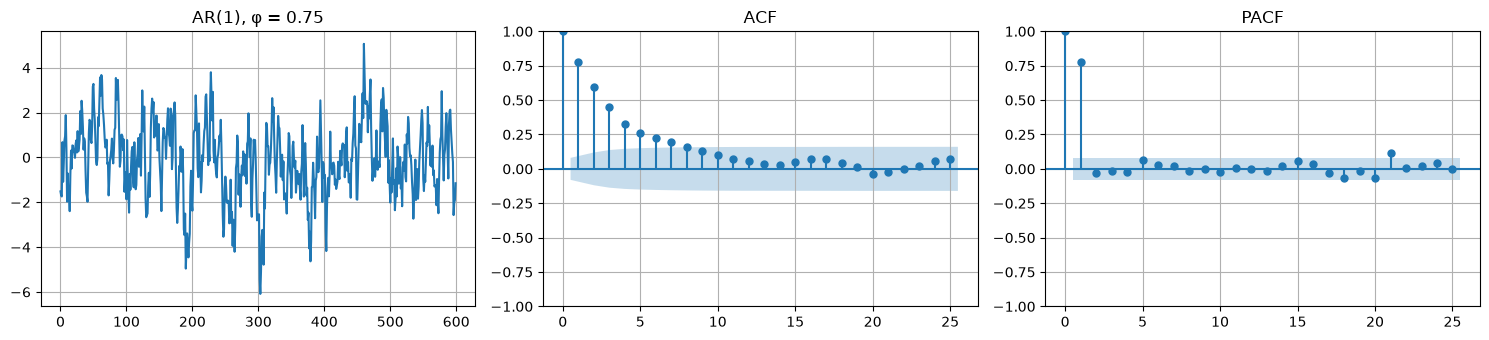

In [3]:
def simular_arma(phi=(), theta=(), n=600, semilla=SEMILLA, burnin=400):
    # statsmodels usa 1 - phi_1 L - ... en el polinomio AR.
    ar = np.r_[1., -np.asarray(phi, dtype=float)]
    ma = np.r_[1., np.asarray(theta, dtype=float)]
    proceso = ArmaProcess(ar, ma)
    if not proceso.isstationary:
        raise ValueError("La parte AR no es estacionaria")
    if not proceso.isinvertible:
        raise ValueError("La parte MA no es invertible")
    rng_local = np.random.default_rng(semilla)
    datos = proceso.generate_sample(nsample=n, burnin=burnin,
                                     distrvs=rng_local.standard_normal)
    return pd.Series(datos, name="Serie simulada")

def mostrar_dependencia(s, titulo, lags=25):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    s.plot(ax=ax[0], title=titulo)
    plot_acf(s, lags=lags, ax=ax[1]); ax[1].set_title("ACF")
    plot_pacf(s, lags=lags, ax=ax[2], method="ywm"); ax[2].set_title("PACF")
    plt.tight_layout(); plt.show()

ar1 = simular_arma(phi=[0.75], semilla=1)
mostrar_dependencia(ar1, "AR(1), φ = 0.75")

### 4.1 Comparar AR(1) positivo y negativo

En AR(1), la ACF teórica es $\rho(k)=\phi^k$. Por ello un coeficiente negativo produce alternancia de signos. La PACF teórica solo tiene un rezago no nulo: el primero.

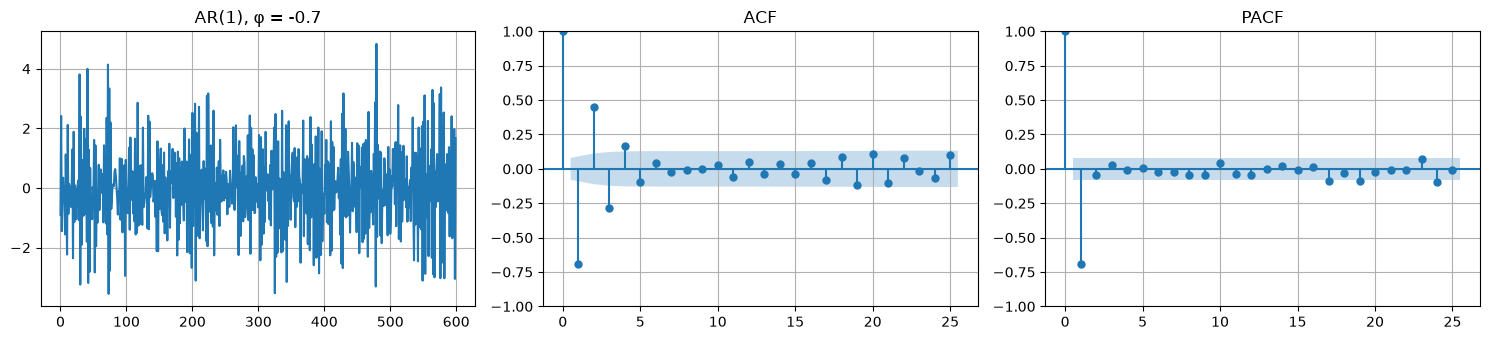

In [4]:
ar1_neg = simular_arma(phi=[-0.7], semilla=2)
mostrar_dependencia(ar1_neg, "AR(1), φ = -0.7")

### 4.2 AR(2): dos valores anteriores

Un AR(2) depende directamente de los dos rezagos anteriores. La ACF puede presentar un decaimiento oscilante y la PACF poblacional se corta después del rezago 2. **No es correcto inferir siempre $p$ contando picos significativos sin considerar la incertidumbre muestral.**

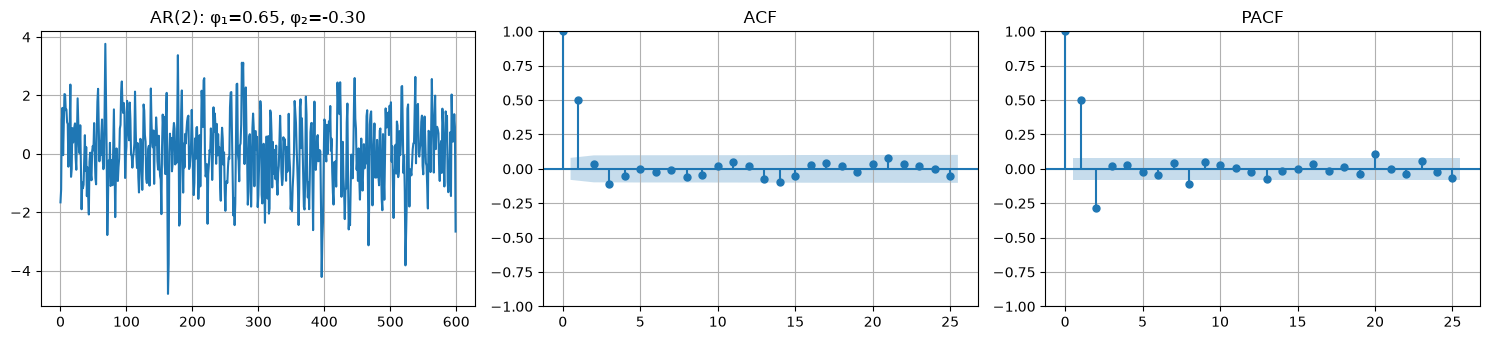

In [5]:
ar2 = simular_arma(phi=[0.65, -0.30], semilla=3)
mostrar_dependencia(ar2, "AR(2): φ₁=0.65, φ₂=-0.30")

## 5. Modelo de media móvil MA(q)

$$X_t=\mu+\varepsilon_t+\theta_1\varepsilon_{t-1}+\cdots+\theta_q\varepsilon_{t-q}.$$

**No confundir:** MA(q) (*moving average* en ARIMA) **no es** el promedio móvil descriptivo de una ventana. Aquí la serie es una combinación de **innovaciones actuales y pasadas**, no de promedios de observaciones.

- Un MA(q) finito es estacionario si las innovaciones son ruido blanco con varianza finita.
- Para identificar de forma única sus parámetros, habitualmente imponemos **invertibilidad**.
- En un MA(q) puro, la **ACF poblacional se corta después del rezago $q$**, mientras la PACF suele decaer.

Para MA(1), $\rho(1)=\theta/(1+\theta^2)$ y $\rho(k)=0$ si $k>1$.

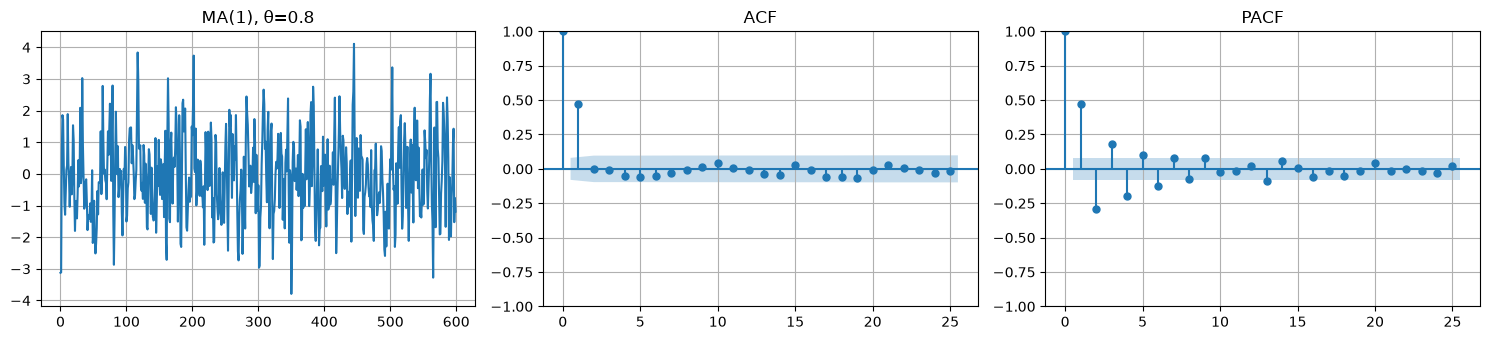

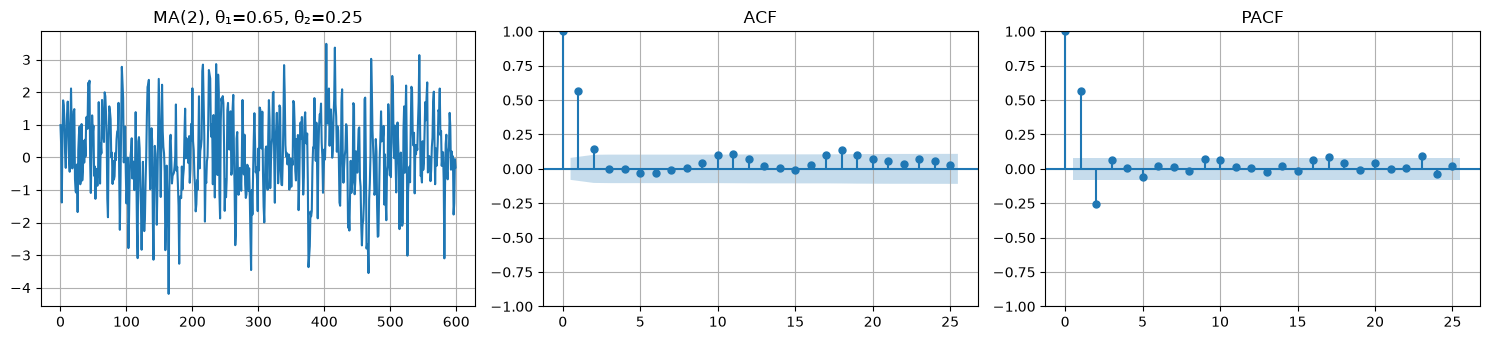

In [6]:
ma1 = simular_arma(theta=[0.8], semilla=4)
mostrar_dependencia(ma1, "MA(1), θ=0.8")
ma2 = simular_arma(theta=[0.65, 0.25], semilla=5)
mostrar_dependencia(ma2, "MA(2), θ₁=0.65, θ₂=0.25")

## 6. ARMA(p,q): combinación de ambas estructuras

$$X_t=c+\sum_{i=1}^{p}\phi_i X_{t-i}+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j}.$$

En un ARMA mixto, **ni la ACF ni la PACF suelen presentar un corte limpio**: ambas pueden decaer. Este es uno de los motivos por los que la identificación visual es solo orientativa.

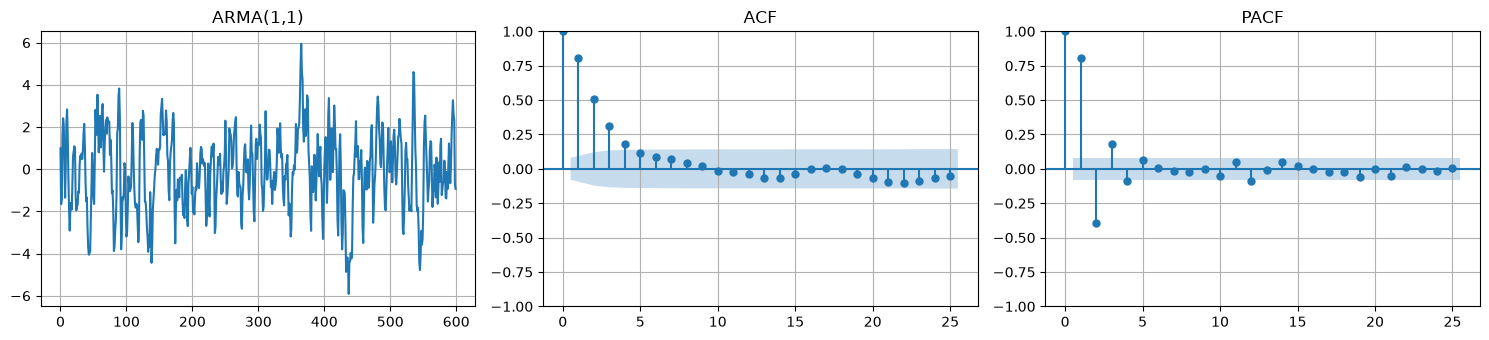

In [7]:
arma11 = simular_arma(phi=[0.65], theta=[0.55], semilla=6)
mostrar_dependencia(arma11, "ARMA(1,1)")

## 7. Tabla de patrones teóricos

| Proceso estacionario | ACF poblacional | PACF poblacional |
|---|---|---|
| Ruido blanco | Cero para $k>0$ | Cero para $k>0$ |
| AR(p) puro | Decae gradualmente / puede oscilar | Se corta tras $p$ |
| MA(q) puro | Se corta tras $q$ | Decae gradualmente / puede oscilar |
| ARMA(p,q) | Habitualmente decae | Habitualmente decae |

**El patrón teórico no es un estimador perfecto del orden.** Con datos finitos, ruido, cambios estructurales o diferenciación excesiva, la lectura se vuelve ambigua.

### 7.1 Confrontar correlaciones teóricas y muestrales

Ahora superpondremos ACF y PACF **teóricas** de un AR(1) y un MA(1), junto con las estimaciones muestrales. Es el experimento que permite distinguir la propiedad matemática de la variabilidad de una muestra.

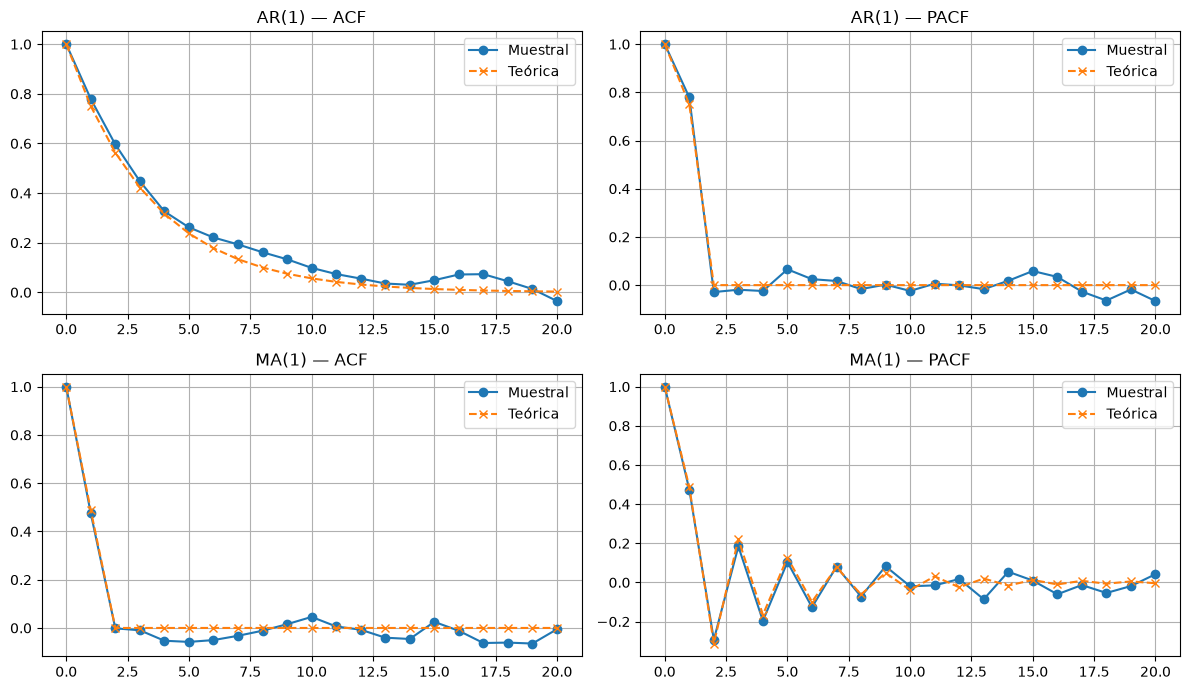

In [8]:
from statsmodels.tsa.stattools import acf, pacf
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for fila, (nombre, s, phi, theta) in enumerate([
    ("AR(1)", ar1, [0.75], []), ("MA(1)", ma1, [], [0.8])
]):
    ar = np.r_[1., -np.asarray(phi)]
    ma = np.r_[1., np.asarray(theta)]
    lag = np.arange(21)
    teoria_acf = arma_acf(ar, ma, lags=21)
    teoria_pacf = arma_pacf(ar, ma, lags=21)
    axs[fila,0].plot(lag, acf(s, nlags=20), 'o-', label="Muestral")
    axs[fila,0].plot(lag, teoria_acf, 'x--', label="Teórica")
    axs[fila,1].plot(lag, pacf(s, nlags=20, method="ywm"), 'o-', label="Muestral")
    axs[fila,1].plot(lag, teoria_pacf, 'x--', label="Teórica")
    axs[fila,0].set_title(f"{nombre} — ACF")
    axs[fila,1].set_title(f"{nombre} — PACF")
    for ax in axs[fila]: ax.legend()
plt.tight_layout(); plt.show()

## 8. Identificación frente a estimación

La **identificación** propone una familia y órdenes $(p,q)$; la **estimación** calcula sus coeficientes $\phi_i,\theta_j$ por máxima verosimilitud (o procedimientos relacionados). Después se realiza el **diagnóstico** de residuos y la **validación predictiva**.

A continuación ajustaremos modelos sobre datos sintéticos. Un modelo verdadero conocido no siempre será seleccionado por AIC/BIC en muestras finitas. El objetivo no es adivinar perfectamente el proceso generador, sino construir un modelo parsimonioso y útil.

In [9]:
modelo_ar = SARIMAX(ar2, order=(2,0,0), trend="n",
                    enforce_stationarity=True, enforce_invertibility=True)
ajuste_ar = modelo_ar.fit(disp=False)
print(ajuste_ar.summary())
print("Parámetros verdaderos: φ₁=0.65, φ₂=-0.30")

                               SARIMAX Results                                
Dep. Variable:         Serie simulada   No. Observations:                  600
Model:               SARIMAX(2, 0, 0)   Log Likelihood                -855.718
Date:                Tue, 03 Nov 2026   AIC                           1717.435
Time:                        08:09:54   BIC                           1730.626
Sample:                             0   HQIC                          1722.570
                                - 600                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6589      0.039     16.915      0.000       0.583       0.735
ar.L2         -0.2965      0.035     -8.459      0.000      -0.365      -0.228
sigma2         1.0138      0.058     17.413      0.0

## 9. De ARMA a ARIMA: diferenciar una serie no estacionaria

ARMA se aplica a series estacionarias (al menos bajo las condiciones requeridas). Si una serie presenta una **raíz unitaria**, puede utilizarse diferenciación ordinaria:

$$\Delta X_t=X_t-X_{t-1},\qquad \Delta^d X_t=(1-B)^d X_t.$$

ARIMA(p,d,q) modela la serie diferenciada mediante una estructura ARMA. **No toda tendencia requiere diferenciación** y diferenciar excesivamente puede introducir autocorrelación artificial.

En un paseo aleatorio con deriva:

$$X_t=X_{t-1}+\delta+\varepsilon_t,\quad\Rightarrow\quad\Delta X_t=\delta+\varepsilon_t.$$

La diferenciación no impide pronosticar niveles: ARIMA integra sus pronósticos de diferencias. Al ajustar `order=(p,1,q)` a la serie original, **no debemos diferenciarla manualmente por segunda vez**.

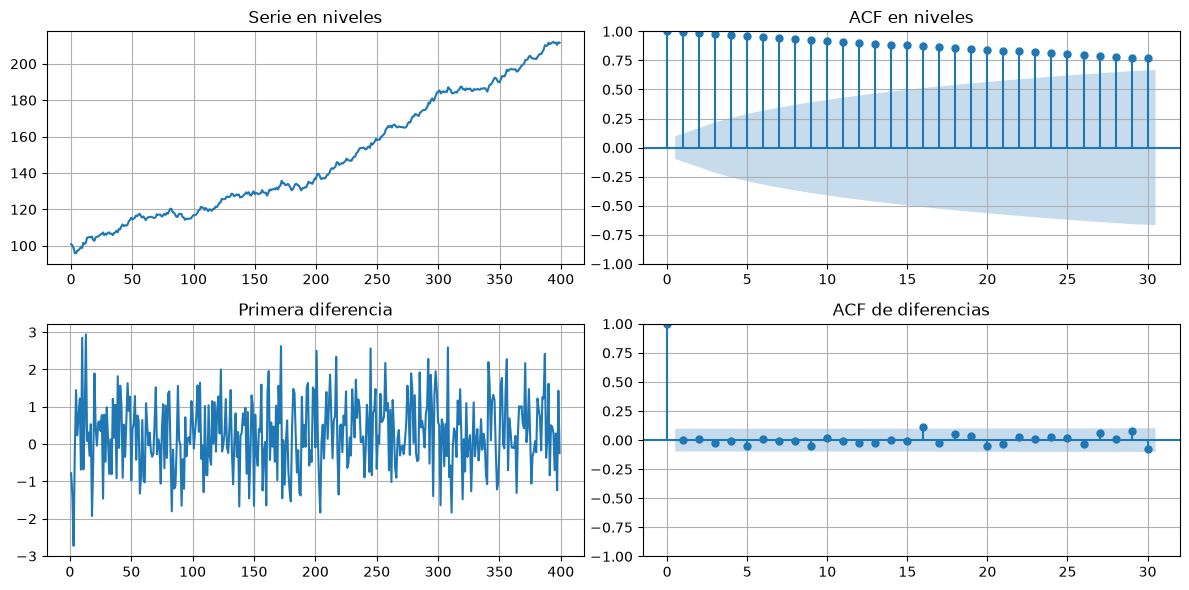

In [10]:
rng = np.random.default_rng(14)
innovaciones = rng.normal(0, 1, 400)
niveles = pd.Series(100 + np.cumsum(0.2 + innovaciones), name="Paseo aleatorio con deriva")
diferencias = niveles.diff().dropna()
fig, ax = plt.subplots(2, 2, figsize=(12, 6))
niveles.plot(ax=ax[0,0], title="Serie en niveles")
plot_acf(niveles, lags=30, ax=ax[0,1]); ax[0,1].set_title("ACF en niveles")
diferencias.plot(ax=ax[1,0], title="Primera diferencia")
plot_acf(diferencias, lags=30, ax=ax[1,1]); ax[1,1].set_title("ACF de diferencias")
plt.tight_layout(); plt.show()

### 9.1 ADF y KPSS: pruebas complementarias

- **ADF:** hipótesis nula de raíz unitaria (bajo la especificación determinista seleccionada).
- **KPSS:** hipótesis nula de estacionariedad alrededor de nivel o tendencia, según la especificación.

Estas pruebas no reemplazan el examen gráfico ni demuestran por sí solas todas las propiedades del proceso. También pueden perder potencia con cambios estructurales o muestras cortas.

In [11]:
def diagnostico_estacionariedad(s):
    s = pd.Series(s).dropna()
    adf = adfuller(s, autolag="AIC", regression="c")
    kps = kpss(s, regression="c", nlags="auto")
    return pd.Series({"ADF estadístico": adf[0], "ADF p-valor": adf[1],
                      "KPSS estadístico": kps[0], "KPSS p-valor": kps[1]})
display(pd.DataFrame({
    "Niveles": diagnostico_estacionariedad(niveles),
    "Diferencias": diagnostico_estacionariedad(diferencias)
}).round(4))

C:\Users\000010478\AppData\Local\Temp\ipykernel_15132\1769619370.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kps = kpss(s, regression="c", nlags="auto")
C:\Users\000010478\AppData\Local\Temp\ipykernel_15132\1769619370.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kps = kpss(s, regression="c", nlags="auto")


,Niveles,Diferencias
ADF estadístico,1.1931,-19.9453
ADF p-valor,0.9959,0.0000
KPSS estadístico,3.1081,0.3006
KPSS p-valor,0.0100,0.1000


## 10. Ajustar ARIMA y pronosticar niveles

Dividimos cronológicamente en entrenamiento y prueba. Compararemos ARIMA(0,1,0) con deriva frente a un ARIMA(1,1,1) con deriva. El paseo aleatorio con deriva es el verdadero generador de nuestros datos; el modelo más complejo no tiene por qué pronosticar mejor.

`trend="t"` introduce una tendencia lineal determinista en la ecuación de niveles de `SARIMAX`; con $d=1$ corresponde a una deriva constante en diferencias.

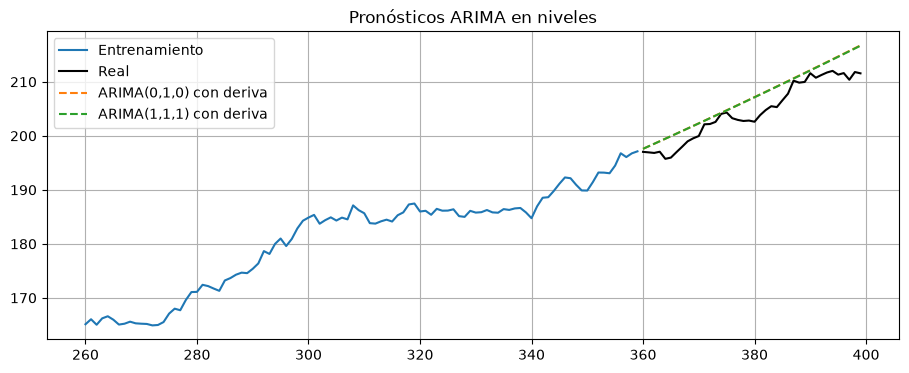

In [12]:
train, test = niveles.iloc[:-40], niveles.iloc[-40:]
modelos_arima = {
    "ARIMA(0,1,0) con deriva": (0,1,0),
    "ARIMA(1,1,1) con deriva": (1,1,1)
}
resultados_arima = {}
for nombre, orden in modelos_arima.items():
    res = SARIMAX(train, order=orden, trend="t").fit(disp=False)
    pred = res.get_forecast(steps=len(test)).predicted_mean
    pred.index = test.index
    resultados_arima[nombre] = {"ajuste": res, "pred": pred}
ax = train.iloc[-100:].plot(label="Entrenamiento")
test.plot(ax=ax, label="Real", color="black")
for nombre, valor in resultados_arima.items():
    valor["pred"].plot(ax=ax, label=nombre, linestyle="--")
ax.legend(); ax.set_title("Pronósticos ARIMA en niveles"); plt.show()

## 11. Selección de órdenes sin depender de un corte visual

Se puede explorar una grilla pequeña de $(p,q)$ manteniendo fijo $d$ y comparar AIC/BIC. El BIC penaliza la complejidad:

$$\mathrm{BIC}=k\log(n)-2\log(\hat L).$$

Aumentar órdenes no garantiza mejorar el BIC ni la capacidad predictiva. La búsqueda debe descartar modelos que no convergen y **verificar residuos y desempeño fuera de muestra**. AIC/BIC deben compararse sobre la misma serie y bajo especificaciones de verosimilitud comparables.

In [13]:
import warnings
busqueda = []
for p in range(4):
    for q in range(4):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = SARIMAX(train, order=(p,1,q), trend="t",
                              enforce_stationarity=True,
                              enforce_invertibility=True).fit(disp=False, maxiter=120)
            if fit.mle_retvals.get("converged", False):
                busqueda.append({"p":p, "d":1, "q":q,
                                 "AIC":fit.aic, "BIC":fit.bic})
        except (ValueError, RuntimeError, np.linalg.LinAlgError):
            pass
tabla = pd.DataFrame(busqueda).sort_values("BIC")
display(tabla.head(10).round(2))

,p,d,q,AIC,BIC
0,0,1,0,998.59,1006.35
4,1,1,0,1000.59,1012.24
1,0,1,1,1000.59,1012.24
5,1,1,1,1002.57,1018.10
8,2,1,0,1002.59,1018.12
2,0,1,2,1002.60,1018.13
12,3,1,0,1004.07,1023.49
3,0,1,3,1004.10,1023.52
6,1,1,2,1004.37,1023.78
9,2,1,1,1004.38,1023.80


## 12. Diagnóstico: ¿queda autocorrelación en los residuos?

Después de ajustar un modelo, buscamos residuos compatibles con innovaciones sin autocorrelación serial. La prueba de **Ljung–Box** contrasta conjuntamente varios rezagos. Un p-valor alto **no prueba independencia**; solo indica falta de evidencia para rechazar la hipótesis de ausencia de autocorrelación en los rezagos examinados.

En modelos integrados, las primeras innovaciones pueden estar afectadas por la inicialización del filtro; conviene examinar su sensibilidad.

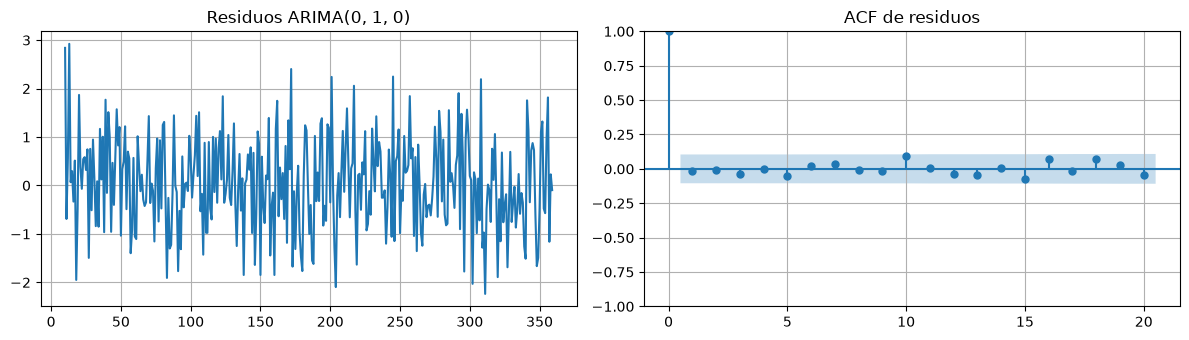

,lb_stat,lb_pvalue
10,5.487619,0.856320
20,13.383084,0.860349


In [14]:
mejor = tabla.iloc[0]
orden_mejor = (int(mejor.p), int(mejor.d), int(mejor.q))
ajuste_mejor = SARIMAX(train, order=orden_mejor, trend="t").fit(disp=False)
residuos = pd.Series(ajuste_mejor.resid).iloc[10:]
fig, ax = plt.subplots(1,2,figsize=(12,3.5))
residuos.plot(ax=ax[0],title=f"Residuos ARIMA{orden_mejor}")
plot_acf(residuos, lags=20, ax=ax[1]); ax[1].set_title("ACF de residuos")
plt.tight_layout(); plt.show()
display(acorr_ljungbox(residuos, lags=[10,20], model_df=orden_mejor[0]+orden_mejor[2], return_df=True))

## 13. De ARIMA a SARIMA: estacionalidad temporal

SARIMA añade términos AR, diferencia y MA **estacionales**:

$$\mathrm{SARIMA}(p,d,q)(P,D,Q)_s.$$

La diferencia estacional es $\Delta_s X_t=X_t-X_{t-s}$. El período $s$ debe interpretarse en la escala temporal del modelo: por ejemplo, $s=12$ para meses con patrón anual. **Estacionalidad observada no implica necesariamente $D=1$**: los términos $P,Q$ también pueden capturar dependencia estacional estacionaria.

Para evitar confundir un patrón de calendario con un patrón de sesiones, utilizaremos datos **mensuales sintéticos** con $s=12$.

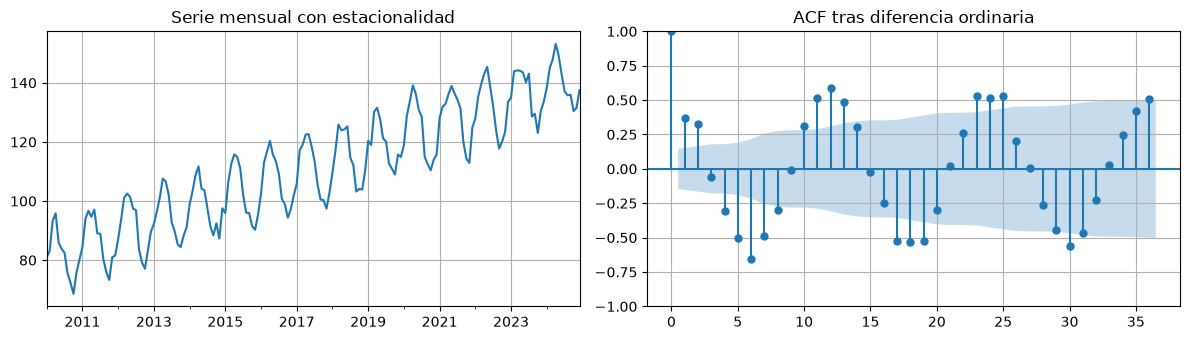

In [15]:
rng = np.random.default_rng(42)
fechas = pd.date_range("2010-01-01", periods=180, freq="MS")
t = np.arange(len(fechas))
# Serie con nivel creciente y componente estacional anual persistente.
y_est = pd.Series(80 + 0.35*t + 12*np.sin(2*np.pi*t/12)
                  + rng.normal(0,3,len(t)), index=fechas, name="Demanda")
fig, ax = plt.subplots(1,2,figsize=(12,3.5))
y_est.plot(ax=ax[0], title="Serie mensual con estacionalidad")
plot_acf(y_est.diff().dropna(), lags=36, ax=ax[1]); ax[1].set_title("ACF tras diferencia ordinaria")
plt.tight_layout(); plt.show()

### 13.1 SARIMA estacional frente a ARIMA no estacional

Entrenaremos hasta una fecha de corte y pronosticaremos los últimos 24 meses. Para esta serie con estacionalidad determinista, un SARIMA estacional puede captar parte del patrón, pero **no necesariamente será la opción más eficiente**. También sería razonable utilizar términos armónicos o indicadores de mes como variables exógenas.

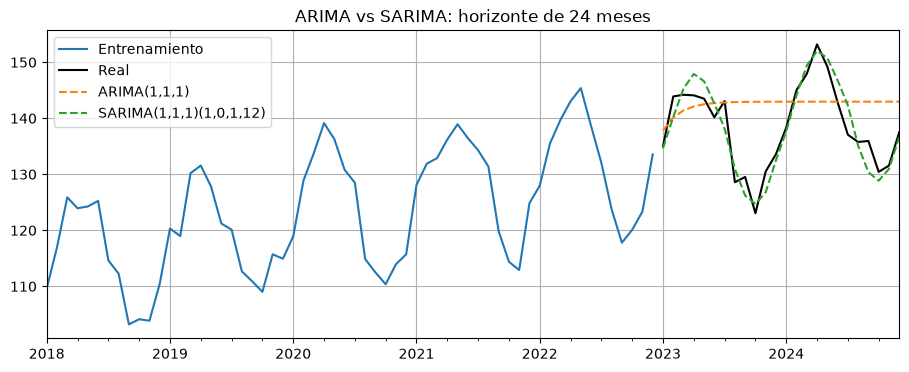

In [16]:
train_s, test_s = y_est.iloc[:-24], y_est.iloc[-24:]
modelos_s = {
    "ARIMA(1,1,1)": ((1,1,1),(0,0,0,0)),
    "SARIMA(1,1,1)(1,0,1,12)": ((1,1,1),(1,0,1,12))
}
res_s = {}
for nombre,(orden,estacional) in modelos_s.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ajuste = SARIMAX(train_s, order=orden, seasonal_order=estacional,
                         enforce_stationarity=True,
                         enforce_invertibility=True).fit(disp=False, maxiter=150)
    pred = ajuste.get_forecast(steps=len(test_s)).predicted_mean
    res_s[nombre] = (ajuste,pred)
ax=train_s.iloc[-60:].plot(label="Entrenamiento")
test_s.plot(ax=ax,label="Real",color="black")
for nombre,(_,pred) in res_s.items():pred.plot(ax=ax,label=nombre,linestyle="--")
ax.legend(); ax.set_title("ARIMA vs SARIMA: horizonte de 24 meses"); plt.show()

## 14. SARIMAX: agregar variables explicativas

**SARIMAX** en `statsmodels` permite combinar una estructura ARIMA/SARIMA de errores con regresores exógenos $Z_t$. Una representación útil es:

$$X_t=\beta^\top Z_t+U_t,$$

$$\Phi(B^s)\phi(B)(1-B)^d(1-B^s)^D U_t=\Theta(B^s)\theta(B)\varepsilon_t.$$

La interpretación exacta depende de la parametrización y de la tendencia especificada. Para pronosticar, **los valores futuros de las variables exógenas deben conocerse o pronosticarse por separado**. Si se utilizan datos futuros reales que no estarían disponibles en producción, se introduce fuga de información.

Crearemos una variable explicativa sintética que afecta la demanda. El modelo no conocerá los parámetros verdaderos.

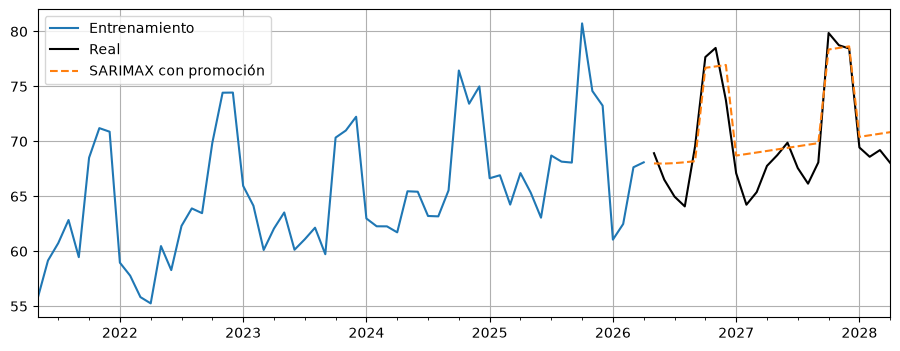

                               SARIMAX Results                                
Dep. Variable:                 Ventas   No. Observations:                  136
Model:               SARIMAX(1, 0, 0)   Log Likelihood                -296.235
Date:                Tue, 03 Nov 2026   AIC                            602.471
Time:                        08:10:00   BIC                            617.034
Sample:                    01-01-2015   HQIC                           608.389
                         - 04-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     17.2332      3.387      5.089      0.000      10.596      23.871
promocion      8.3771      0.489     17.118      0.000       7.418       9.336
tiempo         0.1428      0.011     12.679      0.0

In [17]:
rng = np.random.default_rng(55)
fechas_x = pd.date_range("2015-01-01",periods=160,freq="MS")
t = np.arange(160)
# Una intervención planificada, conocida en el futuro del experimento.
promocion = ((t % 12) >= 9).astype(int)
exo = pd.DataFrame({"promocion":promocion, "tiempo":t},index=fechas_x)
# Errores autocorrelacionados AR(1) para que SARIMAX tenga trabajo real.
error_ar = simular_arma(phi=[0.55], n=160, semilla=55).to_numpy()
y_x = pd.Series(50 + 0.12*t + 9*promocion + 2*error_ar,
                index=fechas_x, name="Ventas")
train_y,test_y = y_x.iloc[:-24],y_x.iloc[-24:]
train_ex,test_ex = exo.iloc[:-24],exo.iloc[-24:]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fit_x = SARIMAX(train_y,exog=train_ex,order=(1,0,0),trend="c").fit(disp=False)
pred_x = fit_x.get_forecast(steps=len(test_y),exog=test_ex).predicted_mean
ax=train_y.iloc[-60:].plot(label="Entrenamiento")
test_y.plot(ax=ax,color="black",label="Real")
pred_x.plot(ax=ax,label="SARIMAX con promoción",linestyle="--")
ax.legend();plt.show()
print(fit_x.summary())

## 15. Valores faltantes y calendario en SARIMAX

A diferencia del cálculo clásico de PACF, el ajuste `SARIMAX` de `statsmodels` puede trabajar con **observaciones endógenas `NaN`** mediante el filtro de Kalman, siempre que se defina una escala temporal regular y una especificación apropiada.

- **Tiempo calendario:** `asfreq("D")` conserva los días y marca huecos con `NaN`. El estado latente del modelo puede evolucionar durante esos intervalos sin observación.
- **Tiempo de negociación:** cada posición representa una sesión; no se agregan filas por festivos.
- **`ffill`:** propaga el último valor conocido; no es equivalente a conservar un faltante.

La ACF/PACF calculada eliminando `NaN` comprime los rezagos: **no debe utilizarse para identificar órdenes en calendario y después ajustar un SARIMAX diario como si fueran la misma escala**.

In [18]:
fechas_bolsa = pd.to_datetime([
    "2026-01-02","2026-01-05","2026-01-06","2026-01-08",
    "2026-01-09","2026-01-12","2026-01-13"
])
precios = pd.Series([100,101,100.5,103,102,104,103.5],index=fechas_bolsa)
calendario = precios.asfreq("D")
comparacion_cal = pd.DataFrame({"Observado":calendario,
                               "ffill (solo ilustrativo)":calendario.ffill()})
display(comparacion_cal)
print("Observaciones por sesión:",len(precios),
      "| posiciones calendario:",len(calendario),
      "| NaN calendario:",int(calendario.isna().sum()))

,Observado,ffill (solo ilustrativo)
2026-01-02,100.0,100.0
2026-01-03,NaN,100.0
2026-01-04,NaN,100.0
2026-01-05,101.0,101.0
2026-01-06,100.5,100.5
2026-01-07,NaN,100.5
2026-01-08,103.0,103.0
2026-01-09,102.0,102.0
2026-01-10,NaN,102.0
2026-01-11,NaN,102.0


Observaciones por sesión: 7 | posiciones calendario: 12 | NaN calendario: 5


## 16. Comparar capacidad predictiva y no solo AIC/BIC

Los criterios de información permiten seleccionar estructuras penalizando parámetros, pero el objetivo de pronóstico requiere evaluar períodos **no utilizados en el ajuste**. Los errores de prueba deben compararse con modelos de referencia (por ejemplo, último valor o pronóstico estacional ingenuo).

Para evitar una conclusión dependiente de un solo corte temporal, puede utilizarse **validación con origen móvil**. En los ejemplos anteriores usamos una partición simple para mantener el tiempo de ejecución razonable.

In [19]:
def metricas(y, pred):
    a,b = np.asarray(y,float),np.asarray(pred,float)
    return {"MAE":np.mean(np.abs(a-b)),"RMSE":np.sqrt(np.mean((a-b)**2))}
comparacion = {}
for nombre,(_,pred) in res_s.items():
    comparacion[nombre] = metricas(test_s,pred)
comparacion["Estacional ingenuo"] = metricas(
    test_s, pd.Series(np.tile(train_s.iloc[-12:].to_numpy(),2),index=test_s.index))
display(pd.DataFrame(comparacion).T.sort_values("RMSE").round(2))

,MAE,RMSE
"SARIMA(1,1,1)(1,0,1,12)",2.32,2.80
Estacional ingenuo,6.93,8.12
"ARIMA(1,1,1)",6.76,8.44
